In [1]:
import numpy as np
from skimage import io
from scipy.interpolate import CubicSpline
from skimage.transform import rotate
import matplotlib.pyplot as plt
plt.style.use('../../src/bip.mplstyle')

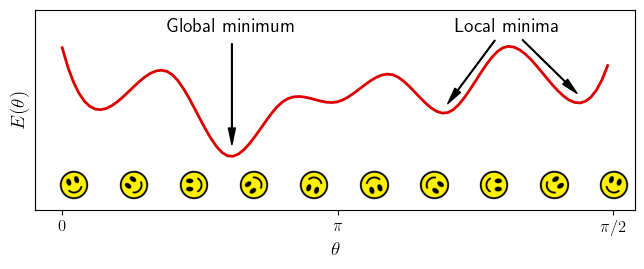

In [2]:
# Figure
fig = plt.figure(figsize=(6,2))
ax = fig.add_axes([0, 0, 1, 1])

# Load smiley and add borders (not to be cropped)
border = 4
smiley = io.imread("smiley.png")
smiley = smiley/255
M, N, _ = smiley.shape
img = np.ones([M+2*border, N+2*border, 3])
img[border:M+border,border:N+border,:] = smiley

# Display N rotated images
N = 10
W = 1/N
size = .15
for n in np.arange(N):
    imax = fig.add_axes([W*n-.01, 0.05, size, size])
    angle = 360 / N * (n+.5)
    img_rotated = rotate(img, angle, mode='constant', cval=1)
    imax.imshow(img_rotated)
    imax.axis('off')

# Curve
data = np.array(((0,3),(1,2),(2,2.5),(3,1),(4,2),(5,2),(6,2.5),(7,1.8),(8,3),(9,2.2),(10,3)))
cs = CubicSpline(data[:,0], data[:,1])
x = np.arange(0, 10, .1)
ax.plot(x, cs(x), color='#d00', linewidth=2)

# Annotations
props = dict(width=.5, headwidth=5, facecolor='black', shrink=.05)
ax.annotate("Global minimum", (3.08,1.1), (3.08,3.3), fontsize=14, ha="center", arrowprops=props)
ax.annotate("Local minima",   (8.2 ,3.3), (8.1,3.3),  fontsize=14, ha="center")
ax.annotate("",               (6.95,1.9), (7.9,3.2),  fontsize=14, ha="center", arrowprops=props)
ax.annotate("",               (9.40,2.1), (8.3,3.2),  fontsize=14, ha="center", arrowprops=props)

# Ticks
ax.set_ylim([0, 3.7])
ax.set_xticks([0, 5, 10], labels=["$0$", r"$\pi$", r"$\pi/2$"])
ax.set_yticks([])
ax.set_xlabel(r"$\theta$", fontsize=14)
ax.set_ylabel(r"$E(\theta)$", fontsize=14)

# Save and display
plt.savefig("optimization.png", bbox_inches="tight")
plt.show()